# Step 2: The four tournaments

Does the community still react to football tournaments as its baseline shrinks?

Four tournaments, each compared with the 28 days right before it: Euro 2020 (played June–July
2021), World Cup 2022 (November–December), Euro 2024 and World Cup 2026. Each also has matched
calendar controls: the same dates in 2023 and 2025, the two years without a tournament.

Two measures, using the average of the 28 days before each tournament as its **baseline**:

- **multiplier** = messages per day during the tournament ÷ baseline (1.5× means 50% busier);
- **absolute lift** = messages per day during the tournament − baseline (extra messages per day).

The controls show how much those calendar weeks move on their own, without a tournament.

Everything uses daily data against a local baseline. Monthly totals would miss the 2022 World
Cup entirely (1,415 messages/day in November and 1,478 in December, against a 2022 average of
1,421), because 2022 was busy all year.

In [1]:
import re
import os
import warnings
import psycopg2
import pandas as pd

warnings.filterwarnings("ignore", message=".*only supports SQLAlchemy.*")

REPO_ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
SQL_PATH = os.path.join(REPO_ROOT, "sql", "02_tournaments.sql")
TABLES_DIR = os.path.join(REPO_ROOT, "outputs", "tables")
os.makedirs(TABLES_DIR, exist_ok=True)

def load_labeled_queries(path):
    with open(path, encoding="utf-8") as f:
        sql = f.read()
    parts = re.split(r"--\s*QUERY:\s*(\w+)", sql)
    return {name: body.strip().rstrip(";") for name, body in zip(parts[1::2], parts[2::2])}

queries = load_labeled_queries(SQL_PATH)
print(f"Loaded {len(queries)} labeled queries: {list(queries.keys())}")

Loaded 5 labeled queries: ['daily_volume', 'event_windows', 'event_metrics', 'event_time_series', 'member_event_activity']


In [2]:
try:
    conn = psycopg2.connect(host="localhost", port=5432, dbname="postgres", user="postgres",
                            options="-c timezone=Europe/Bucharest")
except psycopg2.OperationalError:
    conn = None
    print("No database connection: using the saved tables in outputs/tables/.")
if conn is not None:
    for name, sql in queries.items():
        df = pd.read_sql(sql, conn)
        df.to_csv(os.path.join(TABLES_DIR, f"{name}.csv"), index=False)
        print(f"{name}: {len(df)} rows")
    conn.close()

daily_volume: 2017 rows
event_windows: 12 rows


event_metrics: 12 rows


event_time_series: 852 rows


member_event_activity: 103 rows


In [3]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")
CHARTS_DIR = os.path.join(REPO_ROOT, "outputs", "charts")
os.makedirs(CHARTS_DIR, exist_ok=True)

daily      = pd.read_csv(os.path.join(TABLES_DIR, "daily_volume.csv"), parse_dates=["day"])
windows    = pd.read_csv(os.path.join(TABLES_DIR, "event_windows.csv"), parse_dates=["start_date", "end_date"])
metrics    = pd.read_csv(os.path.join(TABLES_DIR, "event_metrics.csv"), parse_dates=["start_date", "end_date"])
event_time = pd.read_csv(os.path.join(TABLES_DIR, "event_time_series.csv"), parse_dates=["day"])

full_range = pd.date_range(daily["day"].min(), daily["day"].max(), freq="D")
daily = daily.set_index("day").reindex(full_range, fill_value=0).rename_axis("day").reset_index()
print(f"{len(daily):,} calendar days, {(daily['messages'] == 0).sum()} with zero messages")

TOURN = metrics[metrics["kind"] == "tournament"].copy()
CTRL  = metrics[metrics["kind"] == "control"].copy()
COLORS = {"Euro 2020": "#7c3aed", "World Cup 2022": "#c0392b",
          "Euro 2024": "#0891b2", "World Cup 2026": "#059669"}

metrics[["event", "kind", "baseline_mean_per_day", "during_mean_per_day",
         "volume_multiplier", "volume_lift_per_day"]].round(2)

2,236 calendar days, 219 with zero messages


,event,kind,baseline_mean_per_day,during_mean_per_day,volume_multiplier,volume_lift_per_day
0,Euro 2020,tournament,1256.75,1876.29,1.49,619.54
1,World Cup 2022,tournament,1224.50,1790.66,1.46,566.16
2,"World Cup 2026 dates, 2023",control,1070.32,575.90,0.54,-494.42
3,"Euro 2020 dates, 2023",control,1070.32,575.94,0.54,-494.39
4,"Euro 2024 dates, 2023",control,997.36,560.32,0.56,-437.03
5,"World Cup 2022 dates, 2023",control,490.79,445.14,0.91,-45.65
6,Euro 2024,tournament,610.79,991.48,1.62,380.70
7,"World Cup 2026 dates, 2025",control,377.29,426.77,1.13,49.48
8,"Euro 2020 dates, 2025",control,377.29,360.55,0.96,-16.74
9,"Euro 2024 dates, 2025",control,392.11,427.39,1.09,35.28


## The headline result

The multiplier stays similar while the absolute lift shrinks: a similar proportional response to
every tournament, on a baseline that has fallen by two thirds.

In [4]:
summary = TOURN[["event", "baseline_mean_per_day", "during_mean_per_day",
                 "during_peak_per_day", "volume_multiplier", "volume_lift_per_day"]].copy()
summary.columns = ["event", "baseline/day", "during/day", "peak/day", "multiplier", "lift/day"]
print(summary.round(1).to_string(index=False))
print()
print("Matched calendar controls (same dates, tournament-free years):")
print(CTRL[["event", "baseline_mean_per_day", "during_mean_per_day", "volume_multiplier"]]
      .round(2).to_string(index=False))
print()
print(f"Tournament multipliers: {TOURN['volume_multiplier'].min():.2f}-{TOURN['volume_multiplier'].max():.2f}"
      f" (spread {TOURN['volume_multiplier'].max() - TOURN['volume_multiplier'].min():.2f})")
print(f"Control multipliers:    {CTRL['volume_multiplier'].min():.2f}-{CTRL['volume_multiplier'].max():.2f}")
print()
print(f"Absolute lift: {TOURN['volume_lift_per_day'].iloc[0]:.0f}/day in 2021 "
      f"-> {TOURN['volume_lift_per_day'].iloc[-1]:.0f}/day in 2026 "
      f"({TOURN['volume_lift_per_day'].iloc[-1] / TOURN['volume_lift_per_day'].iloc[0] - 1:+.0%})")

         event  baseline/day  during/day  peak/day  multiplier  lift/day
     Euro 2020        1256.8      1876.3      4841         1.5     619.5
World Cup 2022        1224.5      1790.7      3438         1.5     566.2
     Euro 2024         610.8       991.5      2934         1.6     380.7
World Cup 2026         476.0       745.7      1827         1.6     269.8

Matched calendar controls (same dates, tournament-free years):
                     event  baseline_mean_per_day  during_mean_per_day  volume_multiplier
World Cup 2026 dates, 2023                1070.32               575.90               0.54
     Euro 2020 dates, 2023                1070.32               575.94               0.54
     Euro 2024 dates, 2023                 997.36               560.32               0.56
World Cup 2022 dates, 2023                 490.79               445.14               0.91
World Cup 2026 dates, 2025                 377.29               426.77               1.13
     Euro 2020 dates, 2025     

## Chart 1: Daily volume with the tournament windows

Each point is the average of the 7 days around it (a 7-day rolling mean), which smooths out
day-to-day noise. Tournament windows are solid, control windows hatched.

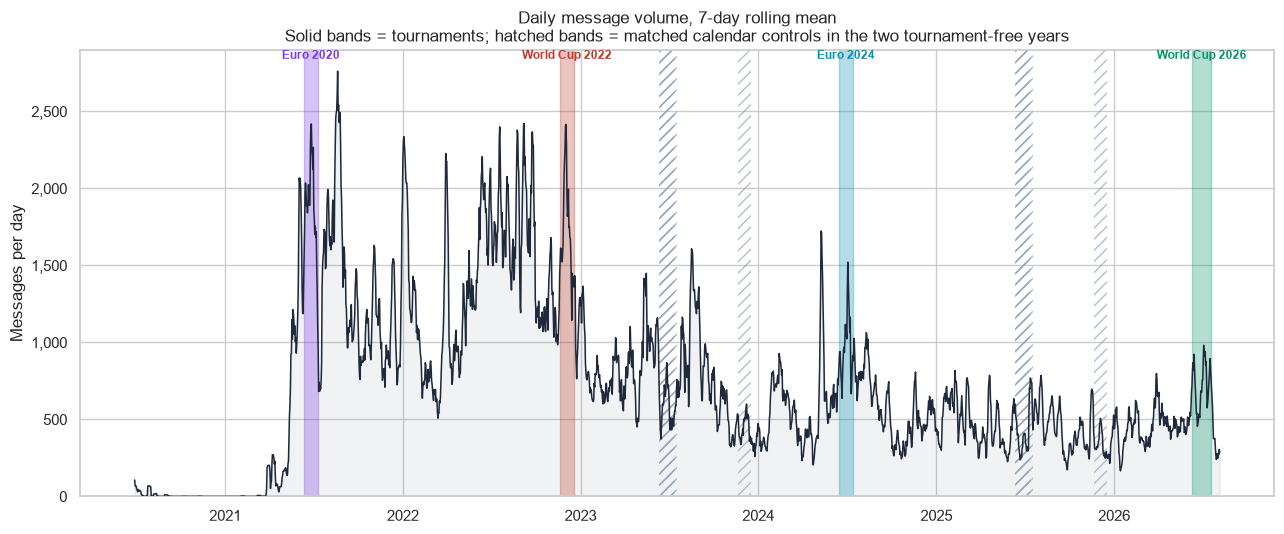

In [5]:
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(daily["day"], daily["messages"].rolling(7, center=True).mean(),
        color="#1e293b", linewidth=1.1, zorder=3)
ax.fill_between(daily["day"], daily["messages"].rolling(7, center=True).mean(),
                color="#1e293b", alpha=0.06, zorder=1)

for _, r in metrics.iterrows():
    if r["kind"] == "tournament":
        ax.axvspan(r["start_date"], r["end_date"], color=COLORS[r["event"]], alpha=0.30, zorder=2)
        ax.annotate(r["event"],
                    (r["start_date"] + (r["end_date"] - r["start_date"]) / 2, ax.get_ylim()[1]),
                    ha="center", va="top", fontsize=8.5, color=COLORS[r["event"]], weight="bold")
    else:
        ax.axvspan(r["start_date"], r["end_date"], facecolor="none", edgecolor="#94a3b8",
                   hatch="///", linewidth=0, alpha=0.7, zorder=2)

ax.set_title("Daily message volume, 7-day rolling mean\n"
             "Solid bands = tournaments; hatched bands = matched calendar controls "
             "in the two tournament-free years", fontsize=12)
ax.set_xlabel("")
ax.set_ylabel("Messages per day")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "06_daily_volume_tournaments.png"), dpi=150)
plt.show()

## Chart 2: Multiplier and absolute lift

The same events measured two ways, pointing in opposite directions, so both are shown.

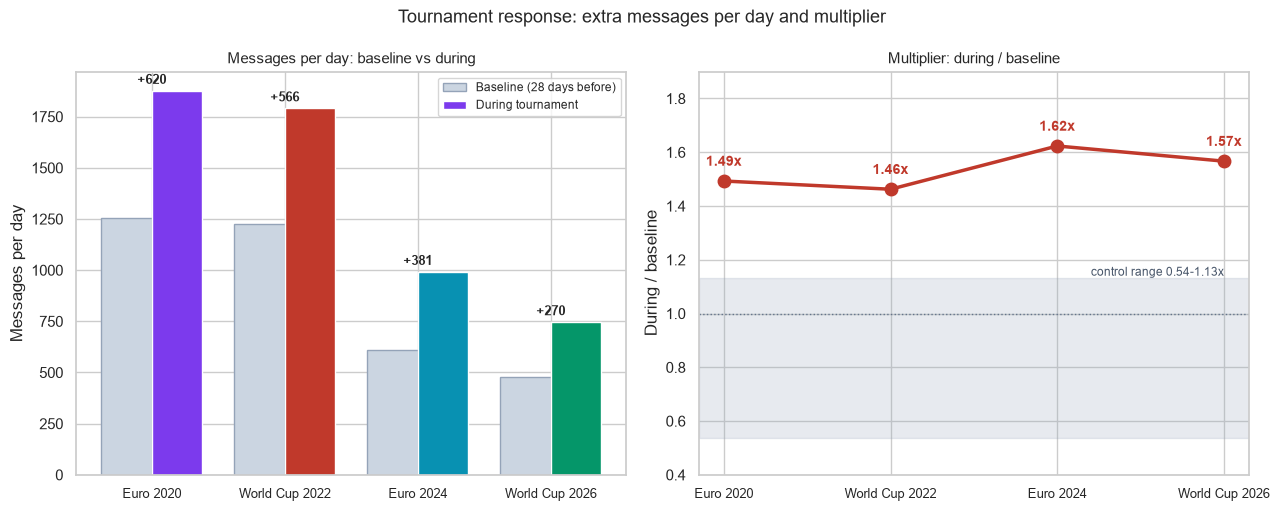

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
x = np.arange(len(TOURN))
labels = [e for e in TOURN["event"]]
bar_colors = [COLORS[e] for e in TOURN["event"]]

w = 0.38
ax1.bar(x - w/2, TOURN["baseline_mean_per_day"], w, label="Baseline (28 days before)",
        color="#cbd5e1", edgecolor="#94a3b8")
ax1.bar(x + w/2, TOURN["during_mean_per_day"], w, label="During tournament", color=bar_colors)
for i, r in enumerate(TOURN.itertuples()):
    ax1.annotate(f"+{r.volume_lift_per_day:.0f}", (i, r.during_mean_per_day),
                 textcoords="offset points", xytext=(0, 5), ha="center", fontsize=9, weight="bold")
ax1.set_xticks(x); ax1.set_xticklabels(labels, fontsize=9)
ax1.set_ylabel("Messages per day")
ax1.set_title("Messages per day: baseline vs during", fontsize=11)
ax1.legend(fontsize=8.5)

ax2.plot(x, TOURN["volume_multiplier"], marker="o", markersize=9, linewidth=2.5, color="#c0392b")
for i, r in enumerate(TOURN.itertuples()):
    ax2.annotate(f"{r.volume_multiplier:.2f}x", (i, r.volume_multiplier), textcoords="offset points",
                 xytext=(0, 11), ha="center", fontsize=10, weight="bold", color="#c0392b")
ctrl_lo, ctrl_hi = CTRL["volume_multiplier"].min(), CTRL["volume_multiplier"].max()
ax2.axhspan(ctrl_lo, ctrl_hi, color="#94a3b8", alpha=0.22)
ax2.annotate(f"control range {ctrl_lo:.2f}-{ctrl_hi:.2f}x", (len(x) - 1, ctrl_hi),
             ha="right", va="bottom", fontsize=8.5, color="#475569")
ax2.axhline(1.0, color="#64748b", linestyle=":", linewidth=1)
ax2.set_xticks(x); ax2.set_xticklabels(labels, fontsize=9)
ax2.set_ylabel("During / baseline")
ax2.set_ylim(0.4, 1.9)
ax2.set_title("Multiplier: during / baseline", fontsize=11)

fig.suptitle("Tournament response: extra messages per day and multiplier", fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "07_multiplier_vs_lift.png"), dpi=150)
plt.show()

## Chart 3: All tournaments on one timeline

Every window on one axis, with day 0 = the tournament's start, each divided by its own 28-day
baseline so tournaments with very different baselines can be compared.

- The tournaments have different lengths (World Cup 2022 is 29 days, World Cup 2026 is 39), so
  each line is solid while its tournament runs and dotted after it ends.
- The controls are shown as a grey min–max band rather than separate lines.

Euro 2020 rises to about 2× before day 0: that's the server's own growth in 2021, which makes
it an unreliable comparison.

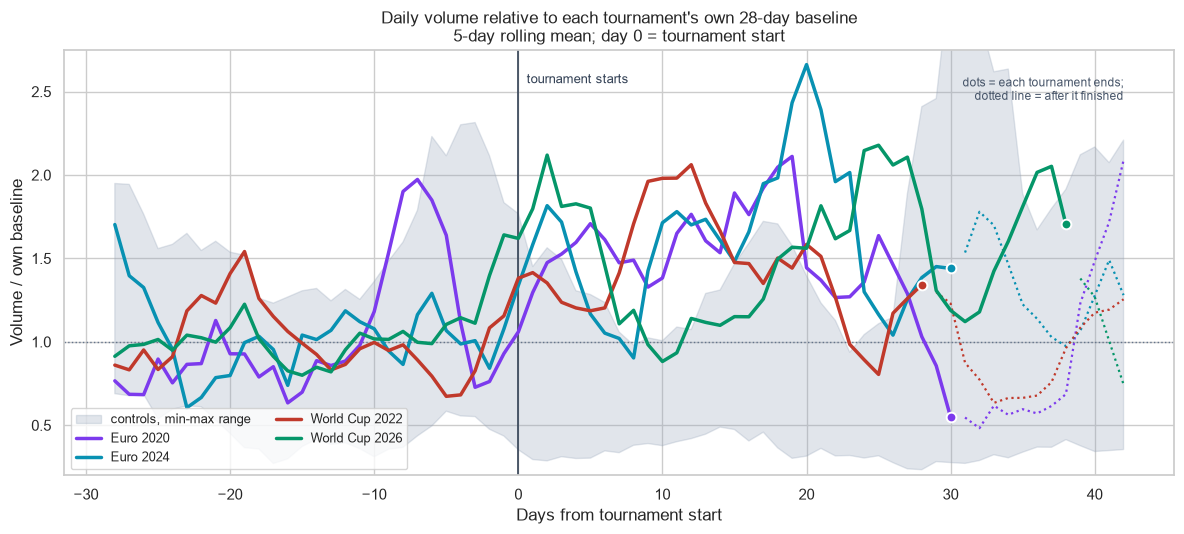

In [7]:
fig, ax = plt.subplots(figsize=(12, 5.5))

ctrl = event_time[event_time["kind"] == "control"]
env = (ctrl.groupby("day_offset")["normalised_to_baseline"]
           .agg(["min", "max"]).rolling(5, center=True, min_periods=1).mean())
ax.fill_between(env.index, env["min"], env["max"], color="#94a3b8", alpha=0.28,
                label="controls, min-max range", zorder=1)

for ev, g in event_time[event_time["kind"] == "tournament"].groupby("event"):
    g = g.sort_values("day_offset")
    smooth = g["normalised_to_baseline"].rolling(5, center=True, min_periods=1).mean()
    length = g["event_length_days"].iloc[0]
    running = g["day_offset"] <= length
    ax.plot(g["day_offset"][running], smooth[running], linewidth=2.5,
            color=COLORS[ev], label=ev, zorder=3)
    ax.plot(g["day_offset"][~running], smooth[~running], linewidth=1.6,
            color=COLORS[ev], linestyle=":", zorder=3)
    end_val = smooth[g["day_offset"] == length]
    if len(end_val):
        ax.plot(length, end_val.iloc[0], marker="o", markersize=7, color=COLORS[ev],
                markeredgecolor="white", markeredgewidth=1.4, zorder=4)

ax.axvline(0, color="#334155", linewidth=1.2, zorder=2)
ax.axhline(1.0, color="#64748b", linestyle=":", linewidth=1, zorder=2)
ax.annotate("tournament starts", (0, 2.55), xytext=(6, 0), textcoords="offset points",
            fontsize=9, color="#334155")
ax.annotate("dots = each tournament ends;\ndotted line = after it finished",
            (42, 2.45), ha="right", fontsize=8.5, color="#475569")
ax.set_title("Daily volume relative to each tournament's own 28-day baseline\n"
             "5-day rolling mean; day 0 = tournament start", fontsize=12)
ax.set_xlabel("Days from tournament start")
ax.set_ylabel("Volume / own baseline")
ax.set_ylim(0.2, 2.75)
ax.legend(fontsize=9, loc="lower left", ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "08_event_time_overlay.png"), dpi=150)
plt.show()

## Participation: more people, or the same people posting more?

In [8]:
breadth = metrics[["event", "kind", "baseline_mean_members_per_day",
                   "during_mean_members_per_day", "members_per_day_multiplier",
                   "baseline_distinct_members", "during_distinct_members",
                   "volume_multiplier"]].copy()
print(breadth.round(2).to_string(index=False))
print()
t = breadth[breadth["kind"] == "tournament"]
print(f"Multiplier, messages per day:       {t['volume_multiplier'].min():.2f}-{t['volume_multiplier'].max():.2f}")
print(f"Multiplier, people posting per day: {t['members_per_day_multiplier'].min():.2f}-{t['members_per_day_multiplier'].max():.2f}")
print()

                     event       kind  baseline_mean_members_per_day  during_mean_members_per_day  members_per_day_multiplier  baseline_distinct_members  during_distinct_members  volume_multiplier
                 Euro 2020 tournament                          16.61                        17.81                        1.07                         22                       22               1.49
            World Cup 2022 tournament                          20.54                        21.34                        1.04                         27                       27               1.46
World Cup 2026 dates, 2023    control                          17.93                        15.67                        0.87                         26                       25               0.54
     Euro 2020 dates, 2023    control                          17.93                        15.87                        0.89                         26                       25               0.54
     Euro 2024 

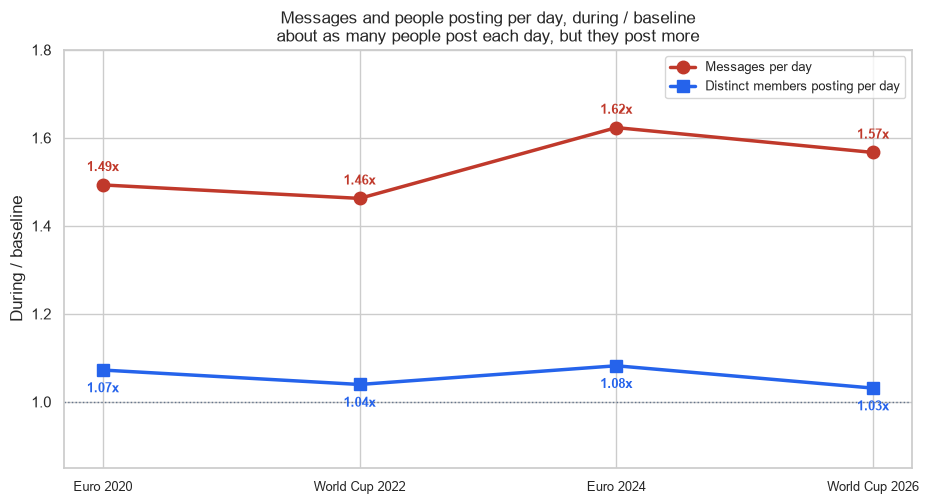

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 5.2))
x = np.arange(len(TOURN))
tb = breadth[breadth["kind"] == "tournament"]
ax.plot(x, tb["volume_multiplier"], marker="o", markersize=9, linewidth=2.5,
        color="#c0392b", label="Messages per day")
ax.plot(x, tb["members_per_day_multiplier"], marker="s", markersize=9, linewidth=2.5,
        color="#2563eb", label="Distinct members posting per day")
for i, r in enumerate(tb.itertuples()):
    ax.annotate(f"{r.volume_multiplier:.2f}x", (i, r.volume_multiplier), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=9, color="#c0392b", weight="bold")
    ax.annotate(f"{r.members_per_day_multiplier:.2f}x", (i, r.members_per_day_multiplier),
                textcoords="offset points", xytext=(0, -16), ha="center", fontsize=9,
                color="#2563eb", weight="bold")
ax.axhline(1.0, color="#64748b", linestyle=":", linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("During / baseline")
ax.set_ylim(0.85, 1.8)
ax.set_title("Messages and people posting per day, during / baseline\n"
             "about as many people post each day, but they post more", fontsize=12)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "09_participation_breadth.png"), dpi=150)
plt.show()

## Decay: how long until volume returns to baseline

The first day after a tournament on which the trailing 7-day mean (the average of that day and
the 6 before it) is back within 5% of that tournament's baseline.

A result of 3 means "3 days or fewer": the trailing mean needs three days of data, so 3 is the
lowest value the measure can return. Three tournaments are at that floor (back to normal
straight away); Euro 2024 took 11 days. World Cup 2026 has only 21 days of data after it.

In [10]:
d = daily.set_index("day")["messages"]
rows = []
for r in TOURN.itertuples():
    base = r.baseline_mean_per_day
    tail = d.loc[r.end_date:].iloc[1:]
    roll = tail.rolling(7, min_periods=3).mean()
    back = roll[roll <= base * 1.05]
    days_avail = len(tail)
    if len(back):
        rows.append((r.event, base, (back.index[0] - r.end_date).days, days_avail, "measured"))
    else:
        rows.append((r.event, base, np.nan, days_avail, f"not reached ({days_avail} days of data after)"))

decay = pd.DataFrame(rows, columns=["event", "baseline/day", "days_to_baseline",
                                    "tail_days_available", "status"])
decay["at_measurement_floor"] = decay["days_to_baseline"] == 3
print(decay.to_string(index=False))
print()
decay.to_csv(os.path.join(TABLES_DIR, "tournament_decay.csv"), index=False)

         event  baseline/day  days_to_baseline  tail_days_available   status  at_measurement_floor
     Euro 2020   1256.750000                 3                 1855 measured                  True
World Cup 2022   1224.500000                 3                 1330 measured                  True
     Euro 2024    610.785714                11                  756 measured                 False
World Cup 2026    475.964286                 3                   21 measured                  True



## Who carries the lift, and can Euro 2020 be separated from growth?

**Who:** each member's messages per day during a tournament minus their own 28-day baseline.
These are shares of the observed excess, not causal effects.

**Euro 2020:** the server was still growing fast in mid-2021, so a flat baseline understates
what June–July would have looked like anyway. Here the baseline is instead a straight-line trend
fitted to the weeks before the tournament, over several fitting windows.

In [11]:
mea = pd.read_csv(os.path.join(TABLES_DIR, "member_event_activity.csv"))
mea["contribution"] = (mea["window_messages"] / mea["window_days"]
                       - mea["baseline_messages"] / mea["baseline_days"])
print("Who carries the lift (messages/day vs each member's own 28-day baseline):")
for ev in ["Euro 2020", "World Cup 2022", "Euro 2024", "World Cup 2026"]:
    g = mea[mea["event"] == ev].sort_values("contribution", ascending=False)
    print(f"  {ev:<15} {int((g['contribution'] > 0).sum()):>2} members up; the top three carry "
          f"{g['contribution'].head(3).sum() / g['contribution'].sum():.0%} of the net lift "
          f"({', '.join(g['pseudonym'].head(3))})")
print()

dv = pd.read_csv(os.path.join(TABLES_DIR, "daily_volume.csv"), parse_dates=["day"]).set_index("day")["messages"]
dv = dv.reindex(pd.date_range(dv.index.min(), dv.index.max()), fill_value=0)
e20 = TOURN[TOURN["event"] == "Euro 2020"].iloc[0]
s, e = e20["start_date"], e20["end_date"]
obs = dv[s:e].mean()
print("Euro 2020 against the server's own growth (observed / expected):")
print(f"  flat 28-day baseline (as reported)   {obs / dv[s - pd.Timedelta(days=28):s - pd.Timedelta(days=1)].mean():.2f}x")
for k in (28, 42, 56, 84):
    pre = dv[s - pd.Timedelta(days=k):s - pd.Timedelta(days=1)]
    slope, icpt = np.polyfit(np.arange(len(pre)), pre.values, 1)
    pred = icpt + slope * np.arange(len(pre), len(pre) + len(dv[s:e]))
    print(f"  straight-line trend, {k:>2}-day fit       {obs / pred.mean():.2f}x")

Who carries the lift (messages/day vs each member's own 28-day baseline):
  Euro 2020       17 members up; the top three carry 54% of the net lift (user_05, user_03, user_07)
  World Cup 2022  23 members up; the top three carry 50% of the net lift (user_01, user_05, user_03)
  Euro 2024       21 members up; the top three carry 48% of the net lift (user_03, user_04, user_13)
  World Cup 2026  22 members up; the top three carry 49% of the net lift (user_01, user_06, user_05)

Euro 2020 against the server's own growth (observed / expected):
  flat 28-day baseline (as reported)   1.49x
  straight-line trend, 28-day fit       0.95x
  straight-line trend, 42-day fit       0.78x
  straight-line trend, 56-day fit       0.86x
  straight-line trend, 84-day fit       1.16x


## Limits

- **2021 isn't a clean comparison.** The server was still growing that summer (1 message a day
  in January, 684 in May, 1,940 in June), so Euro 2020's lift can't be separated from growth: a
  straight-line trend puts its multiplier anywhere from below 1× to above 1×. That leaves three
  clean tournaments (2022, 2024, 2026), too few for a trend.
- **Euro 2020 and Copa América 2021 overlap** almost exactly (11 June – 11 July vs 13 June –
  10 July), so they act as one event.
- **The summer 2023 controls are 0.54–0.56×**, well below 1. That isn't a summer effect: mid-2023
  was the steepest part of the decline, so the 28 days before sit well above the window. A local
  baseline reads low wherever the trend is falling fast.
- **World Cup 2026 decay is cut short** (21 days of data after it).

In [12]:
print("Step 2 summary")
print("-" * 62)
print(f"1. Multiplier, each tournament: "
      f"{', '.join(f'{m:.2f}x' for m in TOURN['volume_multiplier'])}")
print(f"   Controls, same calendar dates: "
      f"{', '.join(f'{m:.2f}x' for m in CTRL['volume_multiplier'])}")
print()
print(f"2. Extra messages per day: "
      f"{', '.join(f'{v:.0f}' for v in TOURN['volume_lift_per_day'])} msgs/day")
print()
print("3. Messages per day about 1.5x; people posting per day about 1.05x.")
print()
print("4. Extra messages per tournament:")
for r in TOURN.itertuples():
    days = (r.end_date - r.start_date).days + 1
    print(f"     {r.event:<20} {r.volume_lift_per_day * days:>10,.0f} extra messages "
          f"({r.volume_lift_per_day * days / 365:>5.1f}/day spread over a year)")

Step 2 summary
--------------------------------------------------------------
1. Multiplier, each tournament: 1.49x, 1.46x, 1.62x, 1.57x
   Controls, same calendar dates: 0.54x, 0.54x, 0.56x, 0.91x, 1.13x, 0.96x, 1.09x, 0.76x

2. Extra messages per day: 620, 566, 381, 270 msgs/day

3. Messages per day about 1.5x; people posting per day about 1.05x.

4. Extra messages per tournament:
     Euro 2020                19,206 extra messages ( 52.6/day spread over a year)
     World Cup 2022           16,418 extra messages ( 45.0/day spread over a year)
     Euro 2024                11,802 extra messages ( 32.3/day spread over a year)
     World Cup 2026           10,521 extra messages ( 28.8/day spread over a year)


## The World Cup and Step 1's headline

Step 1 compares 2022 (a World Cup year) with 2025 (no tournament). How much of the −69% is the
World Cup?

In [13]:
yearly = pd.read_csv(os.path.join(TABLES_DIR, "yearly_totals.csv")).set_index("year")
wc22 = TOURN[TOURN["event"] == "World Cup 2022"].iloc[0]
days22 = (wc22["end_date"] - wc22["start_date"]).days + 1
extra22 = wc22["volume_lift_per_day"] * days22

obs22, obs25 = yearly.loc[2022, "messages_per_day"], yearly.loc[2025, "messages_per_day"]
adj22 = obs22 - extra22 / yearly.loc[2022, "days_observed"]

print(f"2022 observed          {obs22:8.1f} msgs/day")
print(f"  World Cup 2022 added {extra22:8,.0f} messages total over {days22} days")
print(f"  = {extra22 / yearly.loc[2022, 'days_observed']:.1f}/day spread across the year "
      f"({extra22 / yearly.loc[2022, 'total_messages']:.1%} of 2022 volume)")
print(f"2022 tournament-adjusted {adj22:6.1f} msgs/day")
print(f"2025 observed          {obs25:8.1f} msgs/day  (no tournament, no adjustment)")
print()
print(f"2022 -> 2025 as measured: {obs25 / obs22 - 1:+.1%}")
print(f"Tournament-adjusted:      {obs25 / adj22 - 1:+.1%}")
print(f"Tournament effect: {abs((obs25/obs22) - (obs25/adj22)) * 100:.1f} percentage points of the decline.")
print()
print()
print("Alternative: baseline scaled by the same weeks in each year without a tournament:")
for _, c in CTRL[CTRL["event"].str.startswith("World Cup 2022 dates")].iterrows():
    cf = wc22["baseline_mean_per_day"] * c["volume_multiplier"]
    ex = (wc22["during_mean_per_day"] - cf) * days22
    adj = obs22 - ex / yearly.loc[2022, "days_observed"]
    print(f"  {c['event']:<28} excess {ex:>8,.0f}   adjusted decline {obs25 / adj - 1:+.1%}")
print()

2022 observed            1421.4 msgs/day
  World Cup 2022 added   16,418 messages total over 29 days
  = 45.0/day spread across the year (3.2% of 2022 volume)
2022 tournament-adjusted 1376.4 msgs/day
2025 observed             446.7 msgs/day  (no tournament, no adjustment)

2022 -> 2025 as measured: -68.6%
Tournament-adjusted:      -67.5%
Tournament effect: 1.0 percentage points of the decline.


Alternative: baseline scaled by the same weeks in each year without a tournament:
  World Cup 2022 dates, 2023   excess   19,721   adjusted decline -67.3%
  World Cup 2022 dates, 2025   excess   25,111   adjusted decline -67.0%

